In [1]:
### Import all necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

### EDA

In [2]:
### load the dataset
df=pd.read_excel('World_development_mesurement.xlsx')

In [3]:
### shape of dataset
df.shape

(2704, 25)

The dataset contains **2704** rows and **25** columns

In [4]:
### Data information 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   str    
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   str    
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   str    
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   str    
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   float64
 15

* The dataset contents **19**(17+2) numerical columns and **6** objective columns.

In [5]:
### First five rows of the data
df.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


In [6]:
### Descriptive Statistics
df.describe()

,Birth Rate,CO2 Emissions,Days to Start Business,Ease of Business,Energy Usage,Health Exp % GDP,Hours to do Tax,Infant Mortality Rate,Internet Usage,Lending Interest,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban
count,2585.000000,2.125000e+03,1718.000000,185.000000,1.785000e+03,2395.000000,1416.000000,2444.000000,2531.000000,1880.000000,2568.000000,2568.000000,2537.000000,2704.0,2484.000000,2484.000000,2484.000000,2.704000e+03,2678.000000
mean,0.022715,1.423071e+05,39.999418,94.875676,7.723684e+04,0.064170,302.068503,0.032813,0.239747,0.148103,71.159268,66.461838,0.578124,1.0,0.303051,0.623481,0.073465,3.145729e+07,0.562953
std,0.011338,6.159288e+05,57.318588,54.791906,2.599239e+05,0.026325,273.299686,0.029968,0.260132,0.171829,10.708262,9.390217,0.474647,0.0,0.106577,0.069660,0.049541,1.242894e+08,0.245897
min,0.007000,7.000000e+00,1.000000,1.000000,8.000000e+00,0.008000,12.000000,0.002000,0.000000,0.005000,39.000000,37.000000,0.000000,1.0,0.118000,0.474000,0.003000,1.887600e+04,0.082000
25%,0.013000,1.360000e+03,13.000000,48.000000,3.737000e+03,0.046000,156.000000,0.009000,0.000000,0.080000,64.000000,61.000000,0.100000,1.0,0.204750,0.559000,0.033000,8.783360e+05,0.356000
50%,0.020000,8.529000e+03,26.000000,94.000000,1.433800e+04,0.061000,239.000000,0.020000,0.100000,0.120000,75.000000,69.000000,0.500000,1.0,0.299500,0.642500,0.052000,5.800324e+06,0.560000
75%,0.031000,5.910800e+04,45.000000,142.000000,4.185200e+04,0.079000,344.750000,0.053000,0.400000,0.173000,79.000000,73.250000,0.900000,1.0,0.402000,0.676000,0.112000,2.014089e+07,0.765000
max,0.053000,8.286892e+06,694.000000,189.000000,2.727728e+06,0.225000,2600.000000,0.141000,1.000000,4.965000,87.000000,88.000000,2.900000,1.0,0.500000,0.858000,0.244000,1.350695e+09,1.000000


In [7]:
### Check Duplicates
df.duplicated().sum()

np.int64(0)

In [8]:
### Check Null values
df.isnull().sum()

Birth Rate                 119
Business Tax Rate         1281
CO2 Emissions              579
Country                      0
Days to Start Business     986
Ease of Business          2519
Energy Usage               919
GDP                        210
Health Exp % GDP           309
Health Exp/Capita          309
Hours to do Tax           1288
Infant Mortality Rate      260
Internet Usage             173
Lending Interest           824
Life Expectancy Female     136
Life Expectancy Male       136
Mobile Phone Usage         167
Number of Records            0
Population 0-14            220
Population 15-64           220
Population 65+             220
Population Total             0
Population Urban            26
Tourism Inbound            368
Tourism Outbound           471
dtype: int64

In [9]:
### missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

Birth Rate                 4.400888
Business Tax Rate         47.374260
CO2 Emissions             21.412722
Country                    0.000000
Days to Start Business    36.464497
Ease of Business          93.158284
Energy Usage              33.986686
GDP                        7.766272
Health Exp % GDP          11.427515
Health Exp/Capita         11.427515
Hours to do Tax           47.633136
Infant Mortality Rate      9.615385
Internet Usage             6.397929
Lending Interest          30.473373
Life Expectancy Female     5.029586
Life Expectancy Male       5.029586
Mobile Phone Usage         6.176036
Number of Records          0.000000
Population 0-14            8.136095
Population 15-64           8.136095
Population 65+             8.136095
Population Total           0.000000
Population Urban           0.961538
Tourism Inbound           13.609467
Tourism Outbound          17.418639
dtype: float64

* Most columns have some missing values.
* Ease of Business has the highest missing values (93.16%).
* Hours to do Tax and Business Tax Rate have around 47% missing values.
* Days to Start Business, Energy Usage, and Lending Interest also have many missing values.
* Some columns like Population Urban, Birth Rate, and Life Expectancy have fewer missing values.
* Country, Number of Records, and Population Total have no missing values.
* We need to handle these missing values before applying clustering models.

In [10]:
### Drop Ease of Business due to high missing values
df.drop(columns=['Ease of Business'], inplace=True)

In [11]:
df.shape

(2704, 24)

Ease of Business was removed because around 93% of its values were missing. Keeping this column could affect the clustering results after imputation.

In [12]:
df['Number of Records'].unique()

array([1])

Number of Records has the value 1 for all 2704 rows. Since there is no variation in this column, it does not provide any useful information for clustering.

Therefore, we can drop this column.

In [13]:
### Drop Number of Records column
df.drop(columns=['Number of Records'], inplace=True)

In [14]:
df.shape

(2704, 23)

In [15]:
### Convert object columns to numerical values

money_cols = ['Business Tax Rate', 'GDP', 'Health Exp/Capita',
              'Tourism Inbound', 'Tourism Outbound']

for col in money_cols:
    df[col] = df[col].str.replace('$', '', regex=False)
    df[col] = df[col].str.replace(',', '', regex=False)
    df[col] = df[col].str.replace('%', '', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [16]:
df.dtypes

Birth Rate                float64
Business Tax Rate         float64
CO2 Emissions             float64
Country                       str
Days to Start Business    float64
Energy Usage              float64
GDP                       float64
Health Exp % GDP          float64
Health Exp/Capita         float64
Hours to do Tax           float64
Infant Mortality Rate     float64
Internet Usage            float64
Lending Interest          float64
Life Expectancy Female    float64
Life Expectancy Male      float64
Mobile Phone Usage        float64
Population 0-14           float64
Population 15-64          float64
Population 65+            float64
Population Total            int64
Population Urban          float64
Tourism Inbound           float64
Tourism Outbound          float64
dtype: object

All the columns containing numerical information are now converted to numerical data types. Country remains as an object column because it contains country names and will not be used directly for clustering.

In [17]:
df.isnull().sum()

Birth Rate                 119
Business Tax Rate         1281
CO2 Emissions              579
Country                      0
Days to Start Business     986
Energy Usage               919
GDP                        210
Health Exp % GDP           309
Health Exp/Capita          309
Hours to do Tax           1288
Infant Mortality Rate      260
Internet Usage             173
Lending Interest           824
Life Expectancy Female     136
Life Expectancy Male       136
Mobile Phone Usage         167
Population 0-14            220
Population 15-64           220
Population 65+             220
Population Total             0
Population Urban            26
Tourism Inbound            368
Tourism Outbound           471
dtype: int64

The object columns were successfully converted into numerical values. The number of missing values remains the same, so no additional missing values were created during the conversion.

In [18]:
### Fill missing values with median
num_cols = df.select_dtypes(include=['float64', 'int64']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

We used the median to fill the missing values because some columns have very high and very low values. Median is less affected by these extreme values, so it is a safer choice for our data.

In [19]:
# Check missing values after imputation
df.isnull().sum()

Birth Rate                0
Business Tax Rate         0
CO2 Emissions             0
Country                   0
Days to Start Business    0
Energy Usage              0
GDP                       0
Health Exp % GDP          0
Health Exp/Capita         0
Hours to do Tax           0
Infant Mortality Rate     0
Internet Usage            0
Lending Interest          0
Life Expectancy Female    0
Life Expectancy Male      0
Mobile Phone Usage        0
Population 0-14           0
Population 15-64          0
Population 65+            0
Population Total          0
Population Urban          0
Tourism Inbound           0
Tourism Outbound          0
dtype: int64

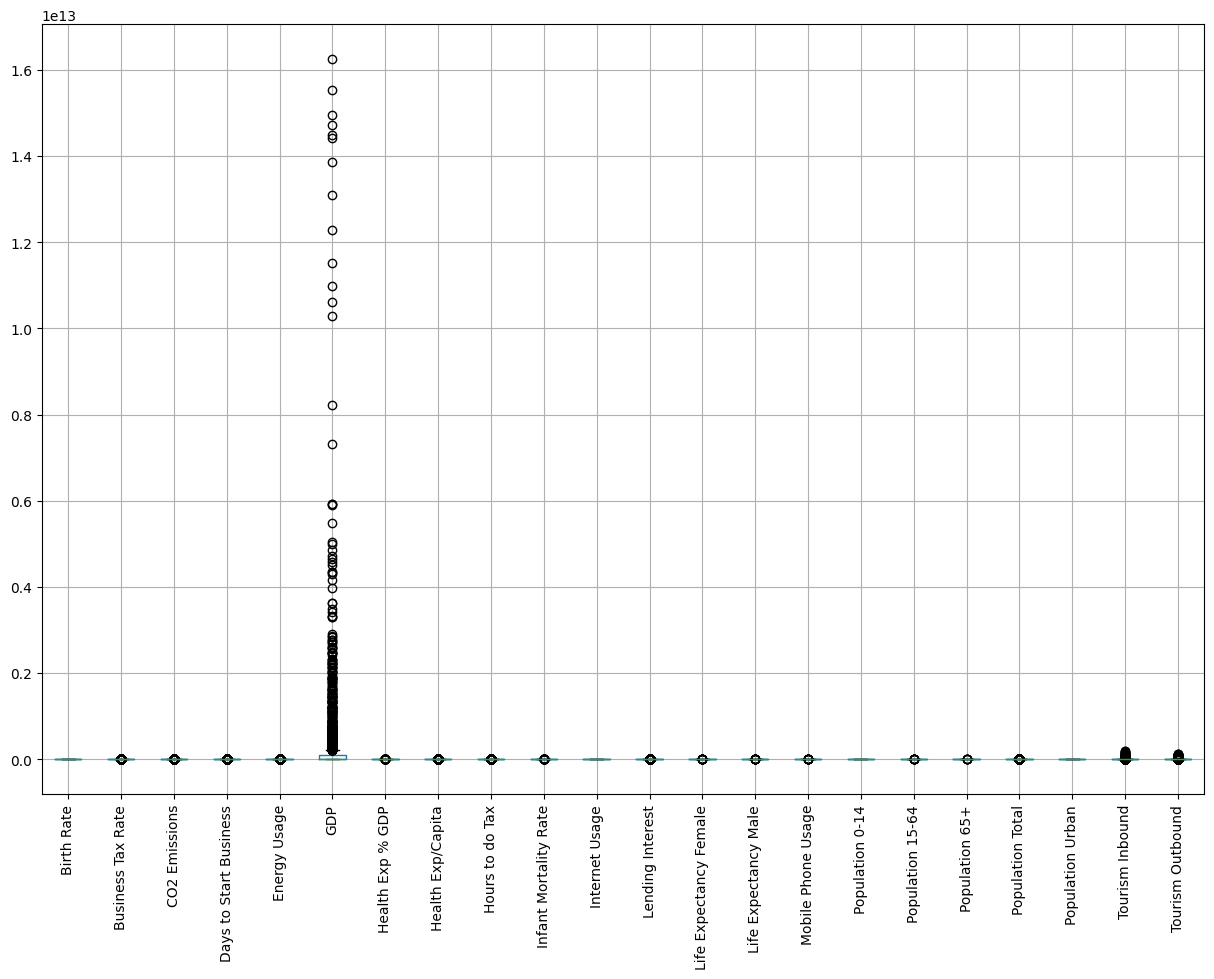

In [20]:
### check outliers
plt.figure(figsize=(15,10))
df.boxplot()
plt.xticks(rotation=90)
plt.show() 

In [21]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(include=['int','float']).columns:
    outlier_capping(df,col)

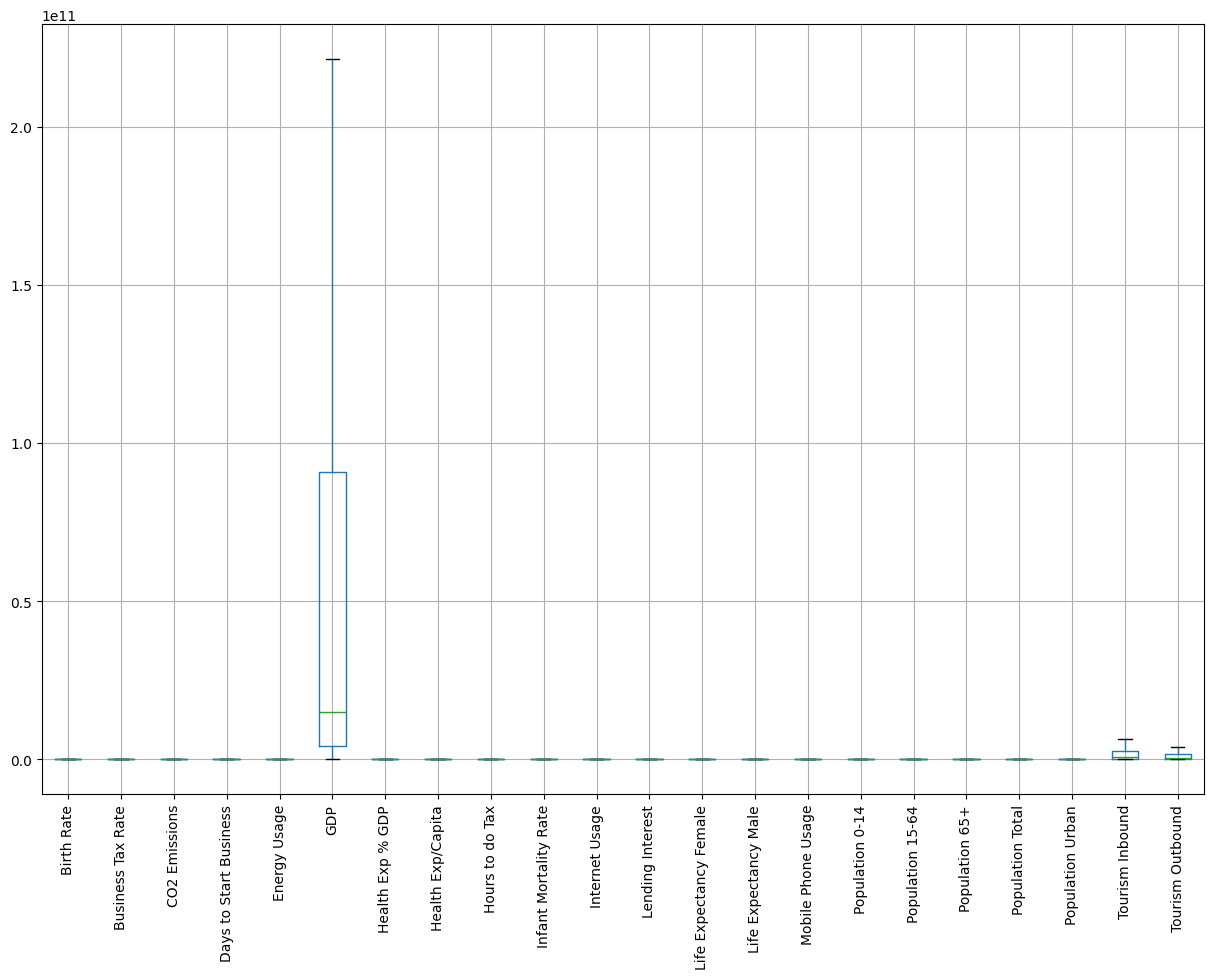

In [22]:
### check outliers after capping
plt.figure(figsize=(15,10))
df.boxplot()
plt.xticks(rotation=90)
plt.show() 

In [23]:
# Correlation analysis
corr = df.select_dtypes(include='number').corr()
corr

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Birth Rate,1.000000,0.071131,-0.351731,0.263394,-0.283022,-0.414817,-0.238268,-0.586558,0.110218,0.870159,...,-0.865210,-0.822416,-0.538916,0.941822,-0.908345,-0.738466,0.012781,-0.592360,-0.505635,-0.453477
Business Tax Rate,0.071131,1.000000,0.098714,0.048059,0.122882,0.085968,0.033481,-0.007675,0.244601,0.082551,...,-0.051172,-0.081643,-0.061025,0.017171,-0.080450,0.076414,0.135898,0.006921,0.065376,0.050578
CO2 Emissions,-0.351731,0.098714,1.000000,-0.072469,0.834030,0.731496,0.056862,0.319254,0.094316,-0.299015,...,0.312254,0.295870,0.142886,-0.396798,0.366395,0.342139,0.629085,0.298178,0.611272,0.693706
Days to Start Business,0.263394,0.048059,-0.072469,1.000000,-0.154774,-0.207639,-0.225340,-0.305008,0.205029,0.260893,...,-0.301963,-0.312340,-0.317268,0.309020,-0.265334,-0.286126,0.011781,-0.230867,-0.264380,-0.227990
Energy Usage,-0.283022,0.122882,0.834030,-0.154774,1.000000,0.801417,0.106609,0.337225,0.052893,-0.224241,...,0.256495,0.250669,0.195398,-0.341386,0.292995,0.321727,0.706726,0.248088,0.651132,0.739654
GDP,-0.414817,0.085968,0.731496,-0.207639,0.801417,1.000000,0.236235,0.561051,0.016179,-0.387134,...,0.415354,0.426889,0.408253,-0.505771,0.417307,0.501678,0.611984,0.414243,0.849741,0.931593
Health Exp % GDP,-0.238268,0.033481,0.056862,-0.225340,0.106609,0.236235,1.000000,0.429149,-0.098304,-0.206844,...,0.221774,0.232064,0.198396,-0.297384,0.095832,0.504073,-0.024224,0.191847,0.302062,0.257110
Health Exp/Capita,-0.586558,-0.007675,0.319254,-0.305008,0.337225,0.561051,0.429149,1.000000,-0.198242,-0.611669,...,0.593077,0.622326,0.583103,-0.664706,0.540245,0.662062,0.004744,0.573658,0.599589,0.613099
Hours to do Tax,0.110218,0.244601,0.094316,0.205029,0.052893,0.016179,-0.098304,-0.198242,1.000000,0.160876,...,-0.135812,-0.158607,-0.084651,0.111258,-0.141352,-0.037649,0.200172,-0.058627,-0.042653,-0.039315
Infant Mortality Rate,0.870159,0.082551,-0.299015,0.260893,-0.224241,-0.387134,-0.206844,-0.611669,0.160876,1.000000,...,-0.924283,-0.901555,-0.571014,0.814703,-0.797798,-0.620503,0.058261,-0.600789,-0.465210,-0.428932


<Axes: >

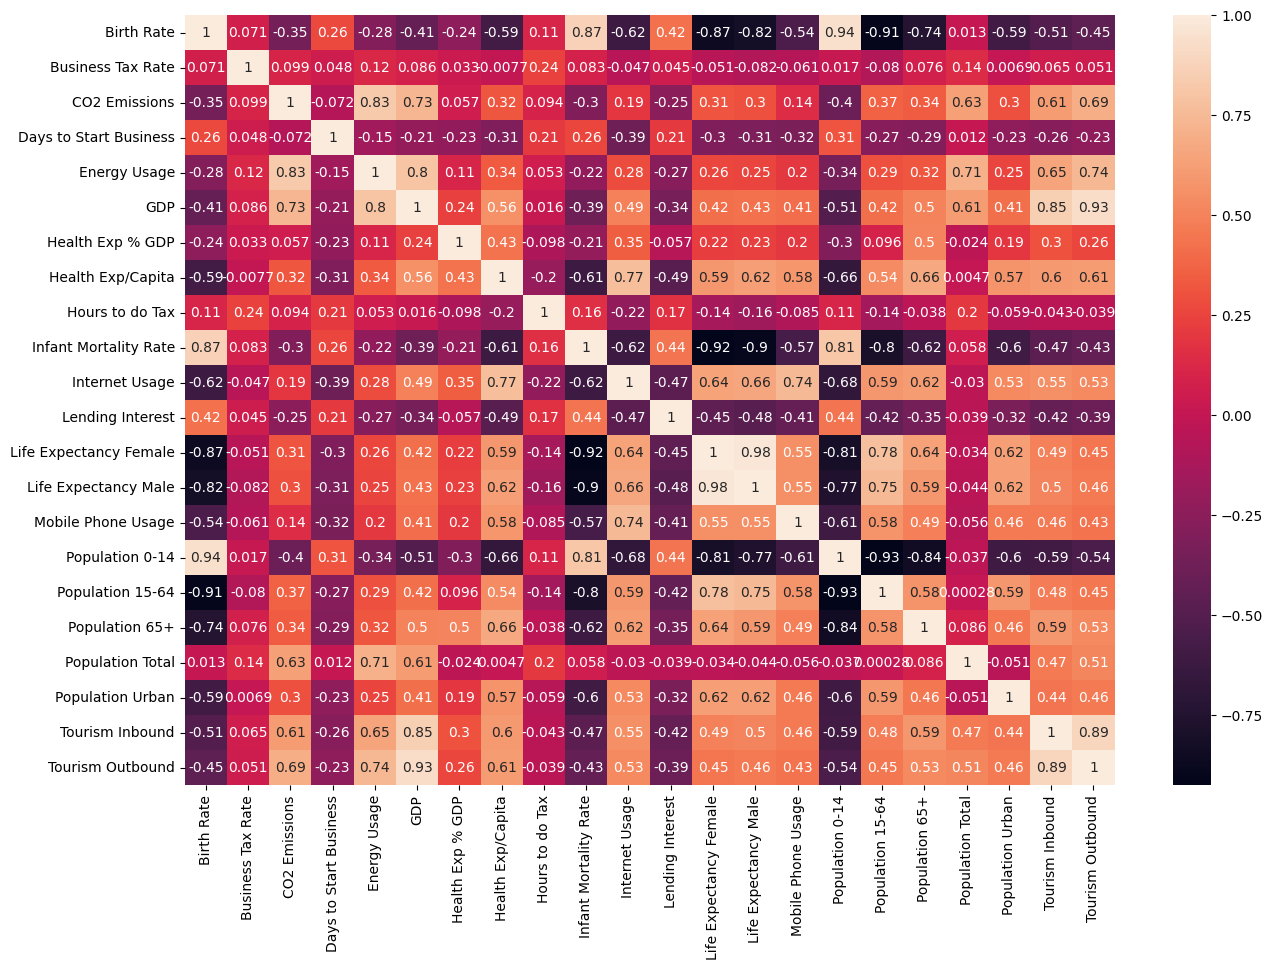

In [24]:
### Heatmap
plt.figure(figsize=(15,10))
sns.heatmap(corr,annot=True)

* Some variables have a strong relationship with each other.
* Life Expectancy Female and Life Expectancy Male have a very strong positive correlation (**0.977**).
* Population 0-14 and Population 15-64 have a strong negative correlation (**-0.926**).
* GDP has a strong positive correlation with Tourism Outbound (**0.932**) and Tourism Inbound (**0.850**).
* Overall, some features are closely related, so we may need to consider feature selection before clustering.

In [25]:
### Feature Scaling

num_col = df.select_dtypes(include=['float64', 'int64'])

std_sca = StandardScaler()

features1 = pd.DataFrame(std_sca.fit_transform(num_col),columns=num_col.columns,index=df.index)

features1.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,-0.233864,-0.064792,1.659733,-0.151075,0.590969,-0.060055,-1.266291,-0.746454,-0.048822,0.092012,...,-0.034833,0.043864,-1.253652,0.384182,-0.089411,-0.684821,1.090800,0.147449,-0.754222,-0.670804
1,2.469335,-0.064792,-0.486142,-0.151075,-0.729010,-0.620533,-1.311467,-0.831569,-0.048822,2.697530,...,-2.334437,-2.472735,-1.253652,1.696192,-1.886942,-0.978160,0.021270,-0.976530,-0.783976,-0.702383
2,1.838589,-0.064792,-0.703087,-0.151075,-1.102414,-0.703641,-0.904880,-0.847248,-0.048822,2.077168,...,-1.376268,-1.487979,-1.253652,1.480788,-1.617312,-0.894348,-0.397993,-0.735385,-0.765161,-0.766886
3,0.396882,-0.064792,-0.630298,-0.151075,-1.112365,-0.661547,-0.724175,-0.540387,-0.048822,0.800996,...,-1.855353,-1.925648,-1.034604,0.785618,-0.568753,-0.894348,-0.710175,-0.126393,-0.699527,-0.660053
4,2.108909,-0.064792,-0.718855,-0.151075,-0.266046,-0.700549,-0.543469,-0.853967,-0.048822,2.289864,...,-1.855353,-1.925648,-1.253652,1.617863,-1.797065,-0.915301,-0.117991,-1.573260,-0.788789,-0.780324


* The numerical features have different ranges.
* StandardScaler brings all numerical features to a similar scale.
* This prevents features with large values, such as GDP and Population Total, from having more influence on the clustering.
* Country is not included because it is a categorical column.

### Model Building & Model Evaluation

#### 1. KMeans Clustering

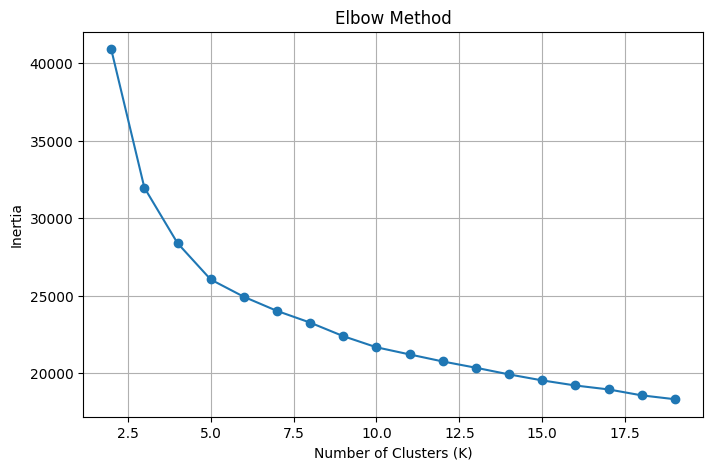

In [26]:
### Elbow Method to Find the Optimal Number of Clusters

inertia = []

for k in range(2, 20):
    kmeans = KMeans(n_clusters=k, random_state=50, n_init=10)
    kmeans.fit(features1)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 20), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

In [27]:
### PCA Dimensionality Reduction
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=100)
features_2d = pca.fit_transform(features1)

### KMeans
kmeans = KMeans(n_clusters=5, random_state=100)
cluster = kmeans.fit(features_2d)
cluster.labels_


array([0, 3, 3, ..., 2, 4, 2], shape=(2704,), dtype=int32)

In [28]:
np.unique(cluster.labels_)

array([0, 1, 2, 3, 4], dtype=int32)

In [29]:
features1['cluster'] = cluster.labels_
features1.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound,cluster
0,-0.233864,-0.064792,1.659733,-0.151075,0.590969,-0.060055,-1.266291,-0.746454,-0.048822,0.092012,...,0.043864,-1.253652,0.384182,-0.089411,-0.684821,1.090800,0.147449,-0.754222,-0.670804,0
1,2.469335,-0.064792,-0.486142,-0.151075,-0.729010,-0.620533,-1.311467,-0.831569,-0.048822,2.697530,...,-2.472735,-1.253652,1.696192,-1.886942,-0.978160,0.021270,-0.976530,-0.783976,-0.702383,3
2,1.838589,-0.064792,-0.703087,-0.151075,-1.102414,-0.703641,-0.904880,-0.847248,-0.048822,2.077168,...,-1.487979,-1.253652,1.480788,-1.617312,-0.894348,-0.397993,-0.735385,-0.765161,-0.766886,3
3,0.396882,-0.064792,-0.630298,-0.151075,-1.112365,-0.661547,-0.724175,-0.540387,-0.048822,0.800996,...,-1.925648,-1.034604,0.785618,-0.568753,-0.894348,-0.710175,-0.126393,-0.699527,-0.660053,3
4,2.108909,-0.064792,-0.718855,-0.151075,-0.266046,-0.700549,-0.543469,-0.853967,-0.048822,2.289864,...,-1.925648,-1.253652,1.617863,-1.797065,-0.915301,-0.117991,-1.573260,-0.788789,-0.780324,3


In [30]:
### Silhouette Score Validation
silhouette_score(features_2d, cluster.labels_)

0.4620649657030689

In [31]:
plot_df = pd.DataFrame(features_2d, columns=['PCA 1', 'PCA 2'])
plot_df['cluster'] = cluster.labels_

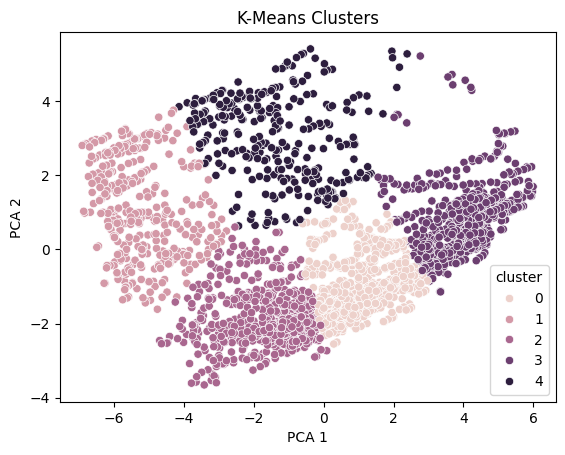

In [32]:
sns.scatterplot(data=plot_df, x="PCA 1", y="PCA 2", hue="cluster")
plt.title("K-Means Clusters")
plt.show()

#### 2. DBSCAN

In [33]:
### Find the eps value
from sklearn.neighbors import NearestNeighbors
n_neigh=NearestNeighbors(n_neighbors=10)
n_neigh.fit(features_2d)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [34]:
distance,index=n_neigh.kneighbors(features_2d)

In [35]:
distance1=sorted(distance[:,1])

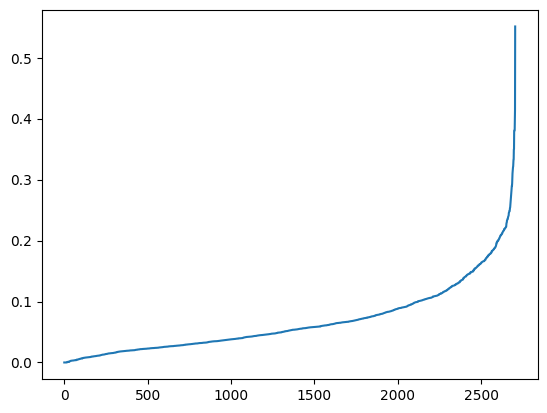

In [36]:
plt.plot(distance1)
plt.show()

In [37]:
eps=np.arange(0.1,0.65,0.05)
eps

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ])

In [38]:
min_nodes=range(1,15)

In [39]:
output=[]
for i in eps:
    for j in min_nodes:
        labels= DBSCAN(eps=i,min_samples=j).fit(features_2d).labels_
        score= silhouette_score(features_2d,labels)
        output.append([i,j,score])
print(output)

[[np.float64(0.1), 1, -0.14641932269889535], [np.float64(0.1), 2, -0.2720430366945239], [np.float64(0.1), 3, -0.3865552956021873], [np.float64(0.1), 4, -0.46366505269200997], [np.float64(0.1), 5, -0.4784671307048484], [np.float64(0.1), 6, -0.43187068808870926], [np.float64(0.1), 7, -0.36783883403509565], [np.float64(0.1), 8, -0.4072274266166923], [np.float64(0.1), 9, -0.40121920533583966], [np.float64(0.1), 10, -0.41696343392739826], [np.float64(0.1), 11, -0.45650200844321787], [np.float64(0.1), 12, -0.42233582193713737], [np.float64(0.1), 13, -0.44618065194250817], [np.float64(0.1), 14, -0.455918145778482], [np.float64(0.15000000000000002), 1, -0.37372542470960374], [np.float64(0.15000000000000002), 2, -0.37622082481378216], [np.float64(0.15000000000000002), 3, -0.4010483659014551], [np.float64(0.15000000000000002), 4, -0.44303411128946674], [np.float64(0.15000000000000002), 5, -0.5101279965079235], [np.float64(0.15000000000000002), 6, -0.5410216267048121], [np.float64(0.1500000000000

In [40]:
eps,min_node,score=sorted(output,reverse=True,key=lambda x:x[2])[0]
print('eps:',eps,'min_node:',min_node,'sil_score:',score)

eps: 0.5000000000000001 min_node: 6 sil_score: 0.24607802496491665


In [41]:
labels= DBSCAN(eps=0.5,min_samples=6).fit(features_2d).labels_
np.unique(labels)

array([-1,  0])

In [42]:
### DBSCAN Cluster Counts

np.unique(labels, return_counts=True)

(array([-1,  0]), array([  20, 2684]))

In [43]:
(np.where(labels<0))

(array([  36,   77,  244,  285,  452,  493,  660,  701,  868,  909, 1076,
        1284, 1492, 1700, 1908, 2116, 2324, 2407, 2532, 2615]),)

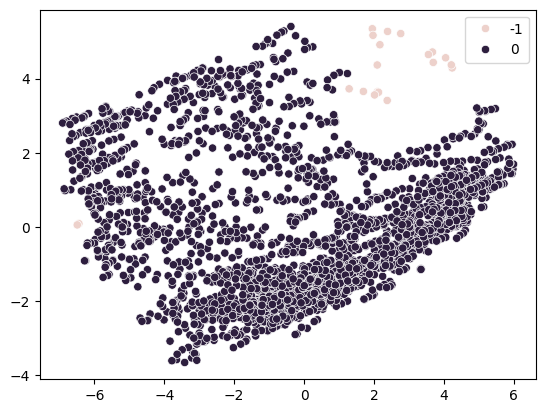

In [44]:
sns.scatterplot(x=features_2d[:, 0], y=features_2d[:, 1],hue=labels)
plt.show()

#### 3.  Hierarchical Clustering

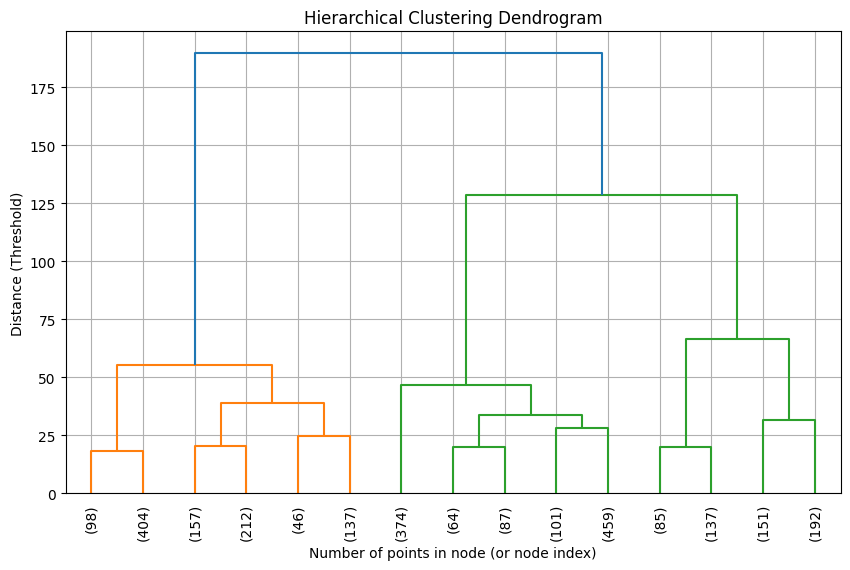

In [45]:
### Hierarchical Clustering Dendrogram

from scipy.cluster.hierarchy import dendrogram, linkage

# Generate the linkage matrix using Ward's minimum variance method
linked = linkage(features_2d, method="ward")

plt.figure(figsize=(10, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=15,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Number of points in node (or node index)")
plt.ylabel("Distance (Threshold)")
plt.grid(True)
plt.show()

In [46]:
### Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering

cluster = AgglomerativeClustering(n_clusters=5,linkage='ward')

cluster.fit(features_2d)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",5
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [47]:
hc_score = silhouette_score(features_2d, cluster.labels_)

print("Hierarchical Clustering Silhouette Score:", hc_score)

Hierarchical Clustering Silhouette Score: 0.413897571578558


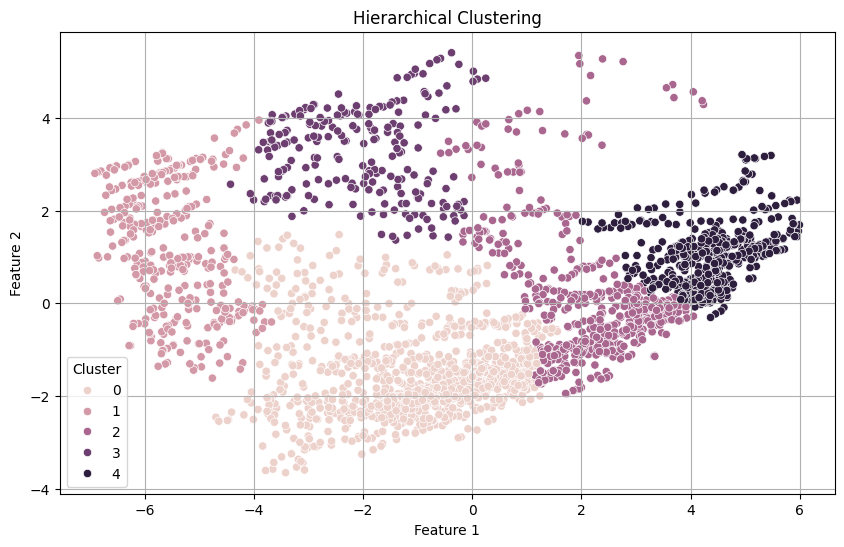

In [48]:
### Visualize Hierarchical Clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=features_2d[:, 0],
    y=features_2d[:, 1],
    hue=cluster.labels_
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Hierarchical Clustering")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

#### 4. Gaussian Mixture Model

In [49]:
from sklearn.mixture import GaussianMixture

In [50]:
### Gaussian Mixture Model

gmm = GaussianMixture(n_components=5,random_state=100)
gmm_labels = gmm.fit_predict(features_2d)

In [51]:
np.unique(gmm_labels, return_counts=True)

(array([0, 1, 2, 3, 4]), array([812, 337, 361, 661, 533]))

In [52]:
### Silhouette Score for GMM

gmm_score = silhouette_score(features_2d, gmm_labels)

print("GMM Silhouette Score:", gmm_score)

GMM Silhouette Score: 0.3243858655858369


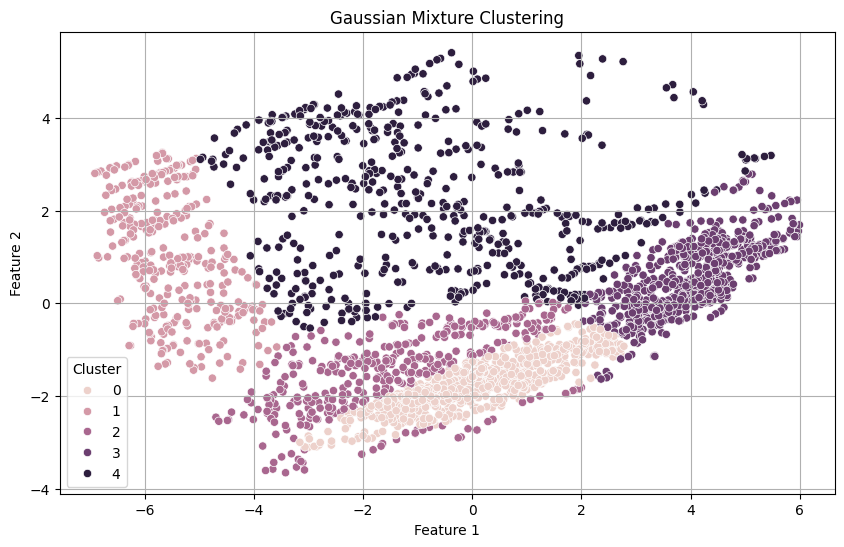

In [53]:
### Visualize GMM Clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(x=features_2d[:, 0],y=features_2d[:, 1],hue=gmm_labels)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Gaussian Mixture Clustering")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

In [54]:
### Mean Shift Clustering
from sklearn.cluster import MeanShift, estimate_bandwidth


# Automatically estimate the optimal search radius (bandwidth)
bandwidth = estimate_bandwidth(features_2d, quantile=0.2, n_samples=500, random_state=100)

ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms_labels = ms.fit_predict(features_2d)
ms_labels


array([1, 1, 1, ..., 0, 3, 0], shape=(2704,))

In [55]:
np.unique(ms_labels)


array([0, 1, 2, 3])

In [56]:
### Silhouette Score for Mean Shift
from sklearn.metrics import silhouette_score

ms_score = silhouette_score(features_2d, ms_labels)
print("Mean Shift Silhouette Score:", ms_score)


Mean Shift Silhouette Score: 0.5203736235227738


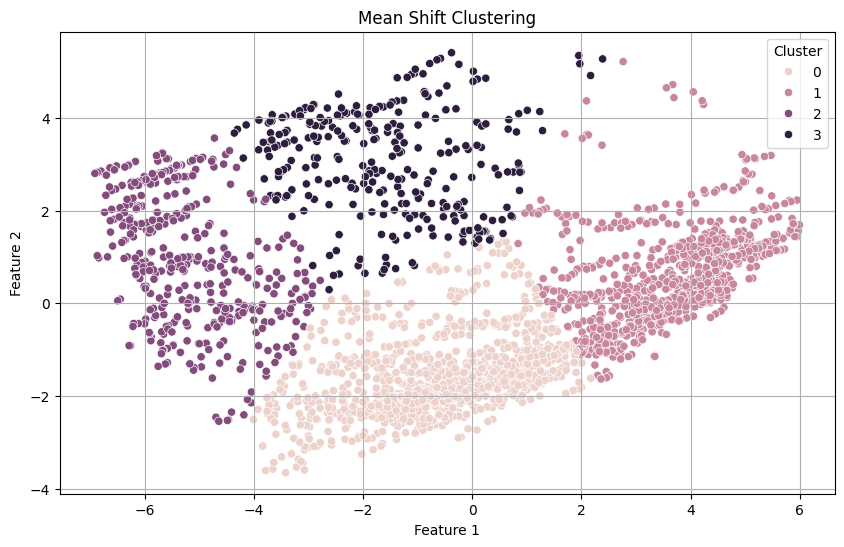

In [57]:
### Visualize Mean Shift Clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=features_2d[:, 0],
    y=features_2d[:, 1],
    hue=ms_labels
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Mean Shift Clustering")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()


In [58]:
df['Cluster'] = ms_labels

In [59]:
### Cluster Profile

cluster_profile = df.groupby('Cluster')[num_col.columns].mean()

cluster_profile

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.017068,40.710177,13175.982743,26.423673,10978.621460,1.954533e+10,0.062781,408.803650,236.042035,0.016535,...,76.630973,70.841593,0.678938,0.263544,0.657440,0.077835,3.834130e+06,0.632783,1.065611e+09,5.405855e+08
1,0.035812,41.386452,8226.351894,34.140356,11632.389495,1.131830e+10,0.056954,66.485649,246.276406,0.064854,...,59.026406,56.252583,0.217451,0.420214,0.546318,0.033457,1.312199e+07,0.351346,2.986234e+08,2.577914e+08
2,0.011802,41.384146,64095.189024,18.373476,35152.755488,1.954710e+11,0.083949,1147.469207,229.132317,0.005420,...,81.885366,76.458537,1.044268,0.175932,0.681741,0.141752,2.106582e+07,0.793859,5.651337e+09,3.760576e+09
3,0.019727,41.968601,86991.071672,30.588311,42479.913823,1.682389e+11,0.052778,249.331058,258.022184,0.025676,...,73.000000,67.197952,0.555631,0.282341,0.654102,0.063549,4.197031e+07,0.599311,3.943423e+09,2.881239e+09


In [60]:
### Number of Countries in Each Cluster

df['Cluster'].value_counts().sort_index()

Cluster
0    1130
1     871
2     410
3     293
Name: count, dtype: int64

In [61]:
cluster_profile.round(2)

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.02,40.71,13175.98,26.42,10978.62,1.954533e+10,0.06,408.80,236.04,0.02,...,76.63,70.84,0.68,0.26,0.66,0.08,3834130.19,0.63,1.065611e+09,5.405855e+08
1,0.04,41.39,8226.35,34.14,11632.39,1.131830e+10,0.06,66.49,246.28,0.06,...,59.03,56.25,0.22,0.42,0.55,0.03,13121993.26,0.35,2.986234e+08,2.577914e+08
2,0.01,41.38,64095.19,18.37,35152.76,1.954710e+11,0.08,1147.47,229.13,0.01,...,81.89,76.46,1.04,0.18,0.68,0.14,21065824.52,0.79,5.651337e+09,3.760576e+09
3,0.02,41.97,86991.07,30.59,42479.91,1.682389e+11,0.05,249.33,258.02,0.03,...,73.00,67.20,0.56,0.28,0.65,0.06,41970309.80,0.60,3.943423e+09,2.881239e+09


In [62]:
### Comparison of Clustering Models

results = pd.DataFrame({
    'Model': [
        'K-Means',
        'DBSCAN',
        'Hierarchical Clustering',
        'GMM',
        'Mean Shift'
    ],
    'Silhouette Score': [
        0.4621,
        0.2461,
        0.4139,
        0.3244,
        0.5204
    ]
})

results

,Model,Silhouette Score
0,K-Means,0.4621
1,DBSCAN,0.2461
2,Hierarchical Clustering,0.4139
3,GMM,0.3244
4,Mean Shift,0.5204


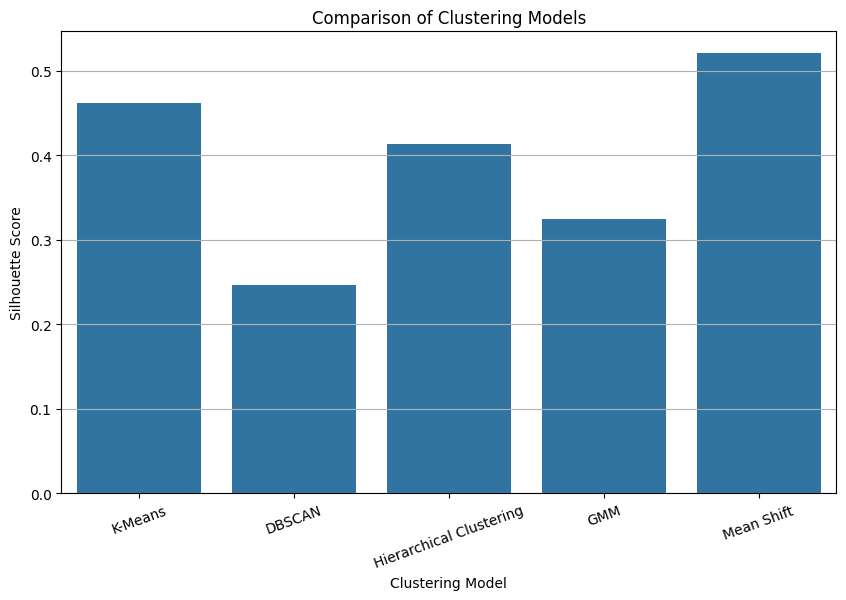

In [63]:
### Comparison of Silhouette Scores

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Model',
    y='Silhouette Score',
    data=results
)

plt.title("Comparison of Clustering Models")
plt.xlabel("Clustering Model")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=20)
plt.grid(True, axis='y')
plt.show()

We compared the five clustering models using the Silhouette Score. Mean Shift achieved the highest score of 0.5204, followed by K-Means with 0.4621. DBSCAN had the lowest score of 0.2461. Based on this comparison, Mean Shift provided the best clustering performance for our dataset

In [64]:
import pickle

pickle.dump(std_sca, open("std_sca.pkl", "wb"))
pickle.dump(pca, open("pca.pkl", "wb"))
pickle.dump(ms, open("mean_shift.pkl", "wb"))